In [4]:
# Notebook deployment
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
DB_FILE = PROJECT_ROOT / "data" / "processed" / "catastrophes.db"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

FIRST_YEAR, LAST_YEAR = 1967, 2026
SOURCE_NOTE = "Source: ICA Historical Normalised Catastrophe List (Sep 2026); ABS CPI via RBA G1."

conn = sqlite3.connect(DB_FILE)

# One consistent chart style for the whole notebook
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "font.size": 10,
})
COLOURS = {"original": "#adb5bd", "cpi_adjusted": "#4dabf7", "normalised": "#1c3d5a"}

*** Question 1: How much does the lost increase? ***

In [5]:
# Take data by SQL
annual = pd.read_sql(
    """
    SELECT year,
           SUM(original_loss)          AS original,
           SUM(cpi_adjusted_loss_2022) AS cpi_adjusted,
           SUM(normalised_loss_2022)   AS normalised
    FROM events
    WHERE has_loss = 1
    GROUP BY year
    """,
    conn,
).set_index("year")

# Years with no catastrophe must count as zero loss, not be dropped
annual = annual.reindex(range(FIRST_YEAR, LAST_YEAR + 1), fill_value=0)

aal_by_decade = annual.groupby(annual.index // 10 * 10).mean() / 1e9  # A$ billion
aal_by_decade.round(2)

,original,cpi_adjusted,normalised
year,,,
1960,0.04,0.57,5.72
1970,0.07,0.64,2.84
1980,0.19,0.53,2.24
1990,0.38,0.74,2.36
2000,0.64,0.94,1.62
2010,2.31,2.78,3.60
2020,3.48,3.45,3.62


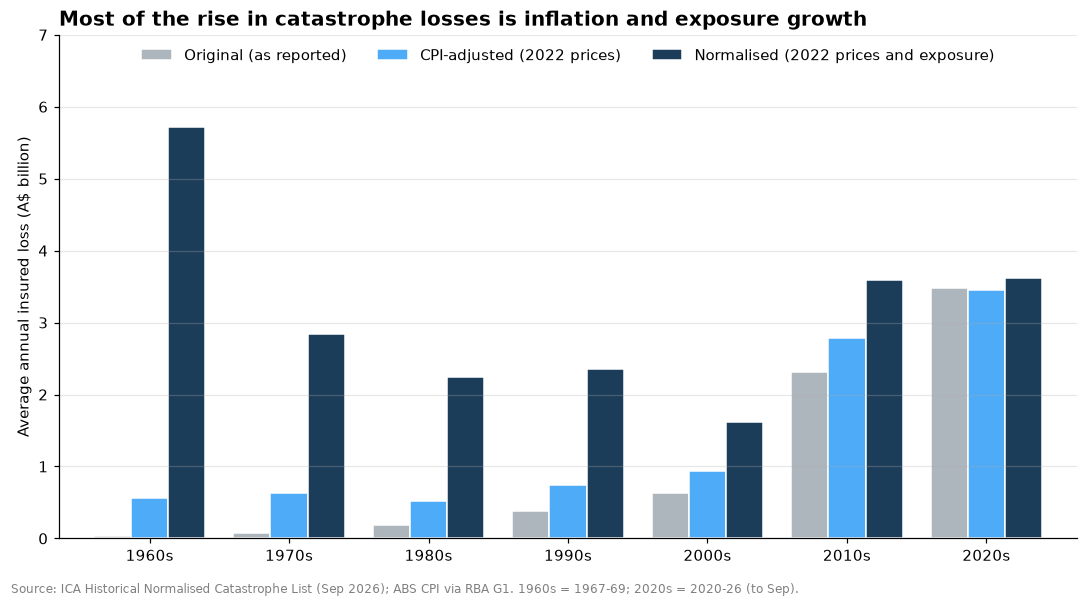

In [6]:
# Graphical representation of the data
fig, ax = plt.subplots(figsize=(10, 5.5))
aal_by_decade.plot.bar(
    ax=ax,
    color=[COLOURS[c] for c in aal_by_decade.columns],
    width=0.8,
    edgecolor="white",
)
ax.set_xticklabels([f"{d}s" for d in aal_by_decade.index], rotation=0)
ax.set_xlabel("")
ax.set_ylabel("Average annual insured loss (A$ billion)")
ax.set_title("Most of the rise in catastrophe losses is inflation and exposure growth", loc="left")
ax.legend(
    ["Original (as reported)", "CPI-adjusted (2022 prices)", "Normalised (2022 prices and exposure)"],
    frameon=False, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.0),
)
ax.set_ylim(0, 7)
ax.grid(axis="y", alpha=0.3)
fig.text(0.01, 0.01, SOURCE_NOTE + " 1960s = 1967-69; 2020s = 2020-26 (to Sep).",
         fontsize=8, color="grey")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG_DIR / "01_aal_by_decade.png", dpi=150)
plt.show()

### Insight 1: inflation and exposure growth explain most of the rise in losses

**Reported catastrophe losses have grown about 50-fold since the 1970s, but once
inflation and exposure growth are removed, the increase is much smaller.**

| Measure (average annual loss) | 1970s | 2020s | Change |
|---|---|---|---|
| Original (as reported) | $0.07bn | $3.48bn | ~50× |
| CPI-adjusted (2022 prices) | $0.64bn | $3.45bn | ~5× |
| Normalised (2022 prices and exposure) | $2.84bn | $3.62bn | +27% |

- **Inflation** accounts for roughly a tenfold rise (original vs CPI-adjusted).
- **Exposure growth** (more and more valuable insured property) accounts for most of
  the rest (CPI-adjusted vs normalised).
- On a normalised basis, the 2010s and 2020s (about $3.6bn a year) are still
  **around 75% higher** than the 1980s–2000s average (about $2.1bn a year).

**Caveats**
- The **1960s** figure ($5.7bn) is based on only three years (1967–69) that include
  two of the costliest events on record (Cyclone Dinah and the 1967 Hobart bushfires).
  Averages over short periods are dominated by single large events.
- The 2020s cover 2020 to September 2026 only.
- ICA's normalisation is a model; it may not capture every change in exposure, and
  smaller events are more completely recorded in recent decades.

**So what:** comparing raw insured losses over time overstates the trend in
catastrophe risk. The higher normalised losses in recent decades suggest a possible
increase in hazard, which is tested more formally in Question 4.